In [1]:
import mne

In [2]:
file_path = "D:/Users/windows/Desktop/Inner Speech Decoding/Dataset/sub-01_ses-01_eeg-epo.fif"
epochs = mne.read_epochs(file_path, preload=True)

Reading D:\Users\windows\Desktop\Inner Speech Decoding\Dataset\sub-01_ses-01_eeg-epo.fif ...
    Found the data of interest:
        t =    -500.00 ...    4000.00 ms
        0 CTF compensation matrices available
Not setting metadata
54 matching events found
No baseline correction applied
0 projection items activated


In [3]:
print(epochs)

<EpochsFIF | 54 events (all good), -0.5 – 4 s (baseline off), ~61.4 MiB, data loaded,
 'arriba': 12
 'abajo': 14
 'derecha': 11
 'izquierda': 17>


In [4]:
# 에포크 객체의 간단한 정보 출력
print(epochs.info)

<Info | 12 non-empty values
 bads: []
 ch_names: A1, A2, A3, A4, A5, A6, A7, A8, A9, A10, A11, A12, A13, A14, ...
 chs: 128 EEG, 1 Stimulus
 custom_ref_applied: True
 dig: 131 items (3 Cardinal, 128 EEG)
 file_id: 4 items (dict)
 highpass: 0.5 Hz
 lowpass: 100.0 Hz
 meas_date: 2019-08-20 10:57:41 UTC
 meas_id: 4 items (dict)
 nchan: 129
 projs: []
 sfreq: 256.0 Hz
 subject_info: <subject_info | >
>


NOTE: tfr_multitaper() is a legacy function. New code should use .compute_tfr(method="multitaper").
Applying baseline correction (mode: logratio)


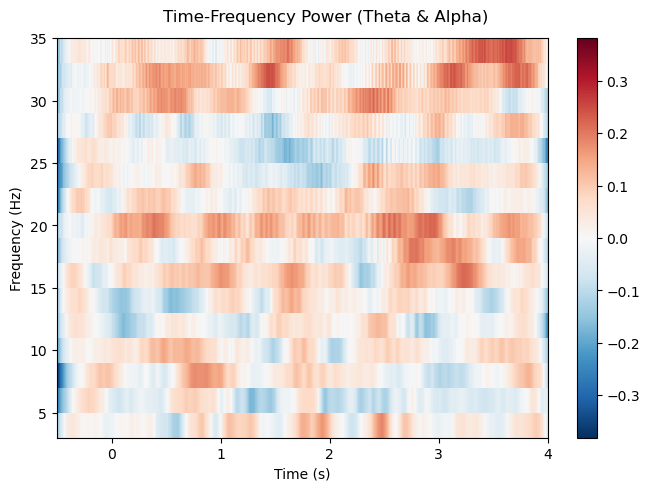

[<Figure size 640x480 with 2 Axes>]

In [8]:
from mne.time_frequency import tfr_multitaper
import numpy as np

# 예시로, Theta (4-8 Hz)와 Alpha (8-13 Hz) 대역을 분석한다고 가정
frequencies = np.arange(4, 36, 2)  # 4, 6, 8, 10, 12 Hz
n_cycles = frequencies / 2  # 주파수에 비례한 사이클 수

# Wavelet Transform을 통해 시간-주파수 분석
power = tfr_multitaper(epochs, freqs=frequencies, n_cycles=n_cycles,
                       time_bandwidth=2.0, return_itc=False, n_jobs=1)

# 첫 번째 에포크에 대한 시각화
power.plot([0], baseline=(-0.5, 0), mode='logratio', title="Time-Frequency Power (Theta & Alpha)")
